# Εργασία 2025-26

**Μάθημα: Αναγνώριση Προτύπων και Μηχανική Μάθηση**  
**Ονοματεπώνυμο: Δημόπουλος Μάριος-Γεώργιος, Παπαχριστοδούλου Γεωργία**  
**ΑΕΜ: 10930, 11177**


# Μέρος Α: Εκτίμηση Παραμέτρων Gaussian Κατανομών (MLE)

In [ ]:
# Βασικές βιβλιοθήκες
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
# Ανάγνωση δεδομένων
data = np.loadtxt("dataset1.csv",delimiter=',')

# Διαχωρισμός χαρακτηριστικών και ετικετών
X = data[:, 0:2]
y = data[:, 2]

print("Αριθμός δειγμάτων:", X.shape[0])


Αριθμός δειγμάτων: 300


In [ ]:
# Εκτίμηση Παραμέτρων Gaussian (MLE)

means = []
covariances = []
classes = np.unique(y)

for c in classes:
    Xc = X[y == c]
    N = Xc.shape[0]

    # Υπολογισμός μέσης τιμής (MLE)
    mu = np.sum(Xc, axis=0) / N

    # Υπολογισμός συνδιακύμανσης (MLE)
    Sigma = np.zeros((2, 2))
    for i in range(N):
        diff = (Xc[i] - mu).reshape(2, 1)
        Sigma += diff @ diff.T
    Sigma /= N

    means.append(mu)
    covariances.append(Sigma)

    print(f"Κλάση {int(c)}")
    print("μ =", mu)
    print("Σ =\n", Sigma)
    print()


Κλάση 0
μ = [29.20903802 16.84988855]
Σ =
 [[46.98591258 22.90532295]
 [22.90532295 48.63133559]]

Κλάση 1
μ = [40.19766916 34.28109099]
Σ =
 [[ 9.42390491 11.48971771]
 [11.48971771 20.10805596]]

Κλάση 2
μ = [27.55232503 34.79318037]
Σ =
 [[13.96874391 11.77433636]
 [11.77433636 25.28848192]]



In [ ]:
# Συνάρτηση Διδιάστατης Gaussian

def gaussian_2d(X, Y, mu, Sigma):
    pos = np.dstack((X, Y))
    Sigma_inv = np.linalg.inv(Sigma)
    det_Sigma = np.linalg.det(Sigma)
    diff = pos - mu

    Z = np.zeros(X.shape)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = np.exp(-0.5 * diff[i, j] @ Sigma_inv @ diff[i, j].T)

    Z /= (2 * np.pi * np.sqrt(det_Sigma))
    return Z


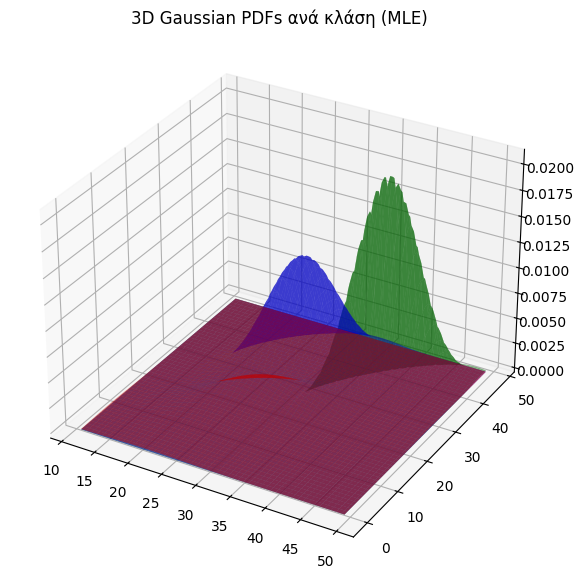

In [ ]:
# Οπτικοποίηση 3D Gaussian Κατανομών

# Δημιουργία πλέγματος
x_vals = np.linspace(X[:,0].min()-2, X[:,0].max()+2, 100)
y_vals = np.linspace(X[:,1].min()-2, X[:,1].max()+2, 100)
Xg, Yg = np.meshgrid(x_vals, y_vals)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

colors = ['red', 'green', 'blue']

for i in range(len(classes)):
    Z = gaussian_2d(Xg, Yg, means[i], covariances[i])
    ax.plot_surface(Xg, Yg, Z, color=colors[i], alpha=0.5)

ax.set_title("3D Gaussian PDFs ανά κλάση (MLE)")
plt.show()


#Μέρος Β: Εκτίμηση Πυκνότητας με Parzen Windows

In [ ]:
#Εισαγωγή βιβλιοθηκών
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, pi, exp

In [ ]:
# Φόρτωση δεδομένων
X = np.loadtxt("dataset2.csv")
N = len(X) # πλήθος δειγμάτων


In [ ]:
# Παράμετροι κανονικής κατανομής N(1,4)
mu = 1
sigma2 = 4
sigma = sqrt(sigma2)

# Πραγματική πυκνότητα πιθανότητας
def true_pdf(x):
    return (1 / (sqrt(2 * pi) * sigma)) * np.exp(-((x - mu) ** 2) / (2 * sigma2))


In [ ]:
#Parzen Window με Υπερκύβο (Uniform Kernel)
def parzen_uniform(x, X, h):

    count = np.sum(np.abs(x - X) <= h / 2)
    return count / (N * h)


In [ ]:
#Parzen Window με Gaussian Kernel
def parzen_gaussian(x, X, h):

    return np.sum(
        (1 / (sqrt(2 * pi) * h)) *
        np.exp(-((x - X) ** 2) / (2 * h ** 2))
    ) / N


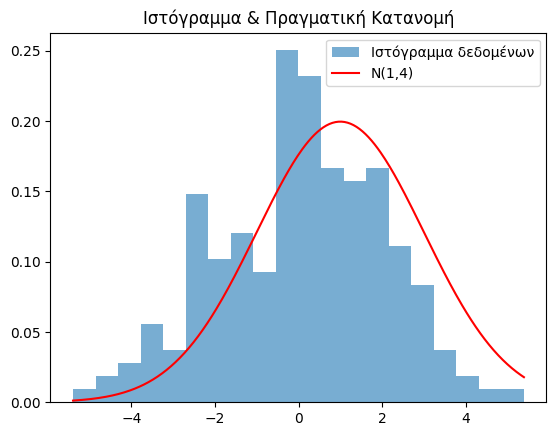

In [ ]:
#Ιστόγραμμα δεδομένων & πραγματική κατανομή

plt.hist(X, bins=20, density=True, alpha=0.6, label="Ιστόγραμμα δεδομένων")

x_vals = np.linspace(min(X), max(X), 300)
plt.plot(x_vals, true_pdf(x_vals), 'r', label="N(1,4)")

plt.legend()
plt.title("Ιστόγραμμα & Πραγματική Κατανομή")
plt.show()


In [ ]:
# Ορισμός τιμών h
h_values = np.arange(0.1, 10.1, 0.1)

errors_uniform = []
errors_gaussian = []


In [ ]:
# Υπολογισμός MSE για κάθε h
for h in h_values:
    est_uniform = np.array([parzen_uniform(x, X, h) for x in X])
    est_gaussian = np.array([parzen_gaussian(x, X, h) for x in X])

    true_vals = true_pdf(X)

    mse_uniform = np.mean((est_uniform - true_vals) ** 2)
    mse_gaussian = np.mean((est_gaussian - true_vals) ** 2)

    errors_uniform.append(mse_uniform)
    errors_gaussian.append(mse_gaussian)


In [ ]:
# Εύρεση βέλτιστου h
best_h_uniform = h_values[np.argmin(errors_uniform)]
best_h_gaussian = h_values[np.argmin(errors_gaussian)]

print("Βέλτιστο h (Υπερκύβος):", best_h_uniform)
print("Βέλτιστο h (Gaussian):", best_h_gaussian)


Βέλτιστο h (Υπερκύβος): 2.8000000000000003
Βέλτιστο h (Gaussian): 0.8


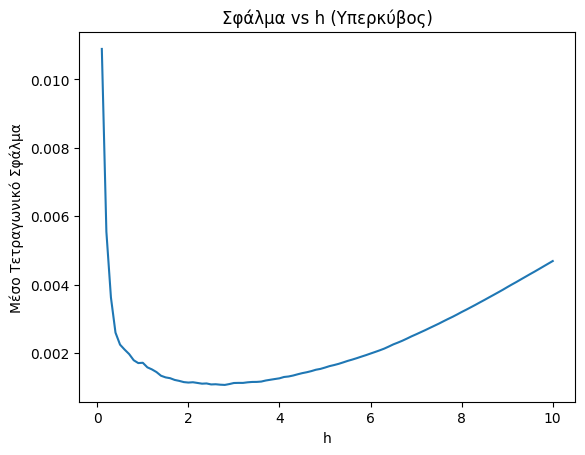

In [ ]:
#Γράφημα σφάλματος – Υπερκύβος

plt.plot(h_values, errors_uniform)
plt.xlabel("h")
plt.ylabel("Μέσο Τετραγωνικό Σφάλμα")
plt.title("Σφάλμα vs h (Υπερκύβος)")
plt.show()


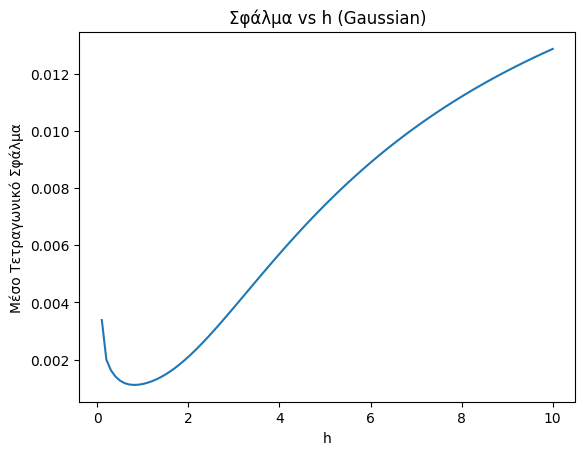

In [ ]:
#Γράφημα σφάλματος – Gaussian Kernel

plt.plot(h_values, errors_gaussian)
plt.xlabel("h")
plt.ylabel("Μέσο Τετραγωνικό Σφάλμα")
plt.title("Σφάλμα vs h (Gaussian)")
plt.show()


#Μέρος Γ: k Nearest Neighbors (KNN)

In [ ]:
#Εισαγωγή βιβλιοθηκών
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Φόρτωση δεδομένων
trainData = np.loadtxt("dataset3.csv", delimiter=",")
testData = np.loadtxt("testset.csv", delimiter=",")

In [ ]:
#Συνάρτηση ευκλείδιας απόστασης
def eucl(x, trainData):
    diff = trainData[:, :2] - x
    distances = np.sqrt(np.sum(diff**2, axis=1))
    return distances

In [ ]:
#Εύρεση k Πλησιέστερων Γειτόνων
def neighbors(x, trainData, k):
    distances = eucl(x, trainData)
    idx = np.argsort(distances)
    return trainData[idx[:k]]

In [ ]:
#Πρόβλεψη Πιθανοτήτων Κλάσεων
def predict(testData, trainData, k):
    probs = []

    for x in testData[:, :2]:
        neigh = neighbors(x, trainData, k)
        labels = neigh[:, 2]

        p0 = np.sum(labels == 0) / k
        p1 = np.sum(labels == 1) / k

        probs.append([p0, p1])

    return np.array(probs)

In [ ]:
#Υπολογισμός Ακρίβειας για Διαφορετικά k εύρους [1,30]
accuracies = []
k_values = range(1, 31)

true_labels = testData[:, 2]

for k in k_values:
    probs = predict(testData, trainData, k)
    predictions = np.argmax(probs, axis=1)
    accuracy = np.mean(predictions == true_labels)
    accuracies.append(accuracy)

In [ ]:
#Βέλτιστο k
best_k = k_values[np.argmax(accuracies)]
best_acc = max(accuracies)

print("Βέλτιστο k:", best_k)
print("Ακρίβεια:", best_acc)

Βέλτιστο k: 11
Ακρίβεια: 0.74


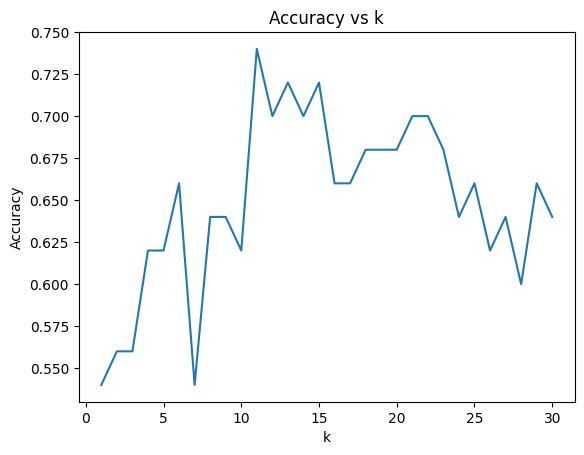

In [ ]:
#Plot k vs Accuracy
plt.plot(k_values, accuracies)
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k")
plt.show()

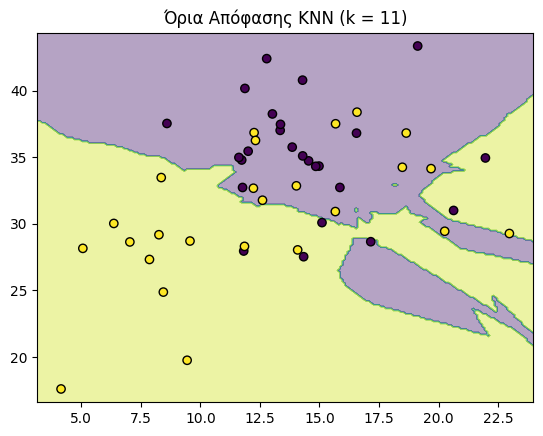

In [ ]:
#Όρια Απόφασης Καλύτερου Ταξινομητή
x_min, x_max = trainData[:,0].min()-1, trainData[:,0].max()+1
y_min, y_max = trainData[:,1].min()-1, trainData[:,1].max()+1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

grid = np.c_[xx.ravel(), yy.ravel()]
grid_labels = np.argmax(predict(
    np.c_[grid, np.zeros(len(grid))], trainData, best_k
), axis=1)

Z = grid_labels.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.4)
plt.scatter(trainData[:,0], trainData[:,1], c=trainData[:,2], edgecolor='k')
plt.title("Όρια Απόφασης KNN (k = {})".format(best_k))
plt.show()